# Parameter-Efficient Transfer Learning for Lightweight Cross-Domain Intrusion Detection in Resource-Constrained 6G-IoT Networks

**Executed core experiments on the user-provided 500,000-row CSV.** Source-target *environment* labels have not been independently verified; therefore, cross-domain experiments and their adaptation metrics are code-only. Same-distribution classifier-only fine-tuning below is clearly identified as a methodological demonstration, **not evidence of cross-domain transfer**. No synthetic traffic or fabricated metrics.

In [1]:
import os, time, warnings, copy, random
os.environ['OMP_NUM_THREADS']='2'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc, precision_recall_curve, classification_report)
from pathlib import Path
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42; np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110,'axes.titlesize':12})
DATA=Path('iot_sfc_research_500k.csv')
if not DATA.exists(): DATA=Path('/mnt/data/iot_sfc_research_500k.csv')
assert DATA.exists(), 'Place CSV alongside this notebook or update DATA'
print('Source:',DATA,'| Torch:',torch.__version__,'| CPU threads:',torch.get_num_threads())

Source: iot_sfc_research_500k.csv | Torch: 2.10.0+cpu | CPU threads: 2


## 1. Dataset verification — actual supplied data

In [2]:
df=pd.read_csv(DATA, low_memory=False)
print('Shape:',df.shape,'CSV MB:',round(DATA.stat().st_size/1024**2,2))
print('Duplicates:',int(df.duplicated().sum()))
print('Attack value counts:\n',df['attack'].value_counts(dropna=False).to_string())
print('Attack categories:',df['type_of_attack'].nunique(dropna=True),'Log types:',df['log_type'].nunique(dropna=True))
print('All columns:',df.columns.tolist())

Shape: (500000, 87) CSV MB: 151.88


Duplicates: 0
Attack value counts:
 attack
0    382752
1    117248
Attack categories: 15 Log types: 19
All columns: ['ts', 'uid', 'orig_h', 'orig_p', 'resp_h', 'resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'orig_pkts', 'resp_pkts', 'orig_ip_bytes', 'resp_ip_bytes', 'conn_state', 'history', 'local_orig', 'local_resp', 'missed_bytes', 'query', 'qclass', 'qclass_name', 'qtype', 'qtype_name', 'rcode', 'rcode_name', 'AA', 'TC', 'RD', 'RA', 'answers', 'TTLs', 'rejected', 'method', 'host', 'uri', 'referrer', 'http_version', 'user_agent', 'request_body_len', 'response_body_len', 'status_code', 'status_msg', 'auth_attempts', 'client', 'server', 'ssl_version', 'cipher', 'curve', 'server_name', 'resumed', 'established', 'validation_status', 'subject', 'issuer', 'topic', 'payload', 'qos', 'mqtt_client_id', 'mqtt_status', 'note', 'msg', 'sub', 'src', 'dst', 'p', 'weird_name', 'weird_addl', 'analyzer_name', 'failure_reason', 'fuid', 'mime_type', 'filename', 'file_duration', '

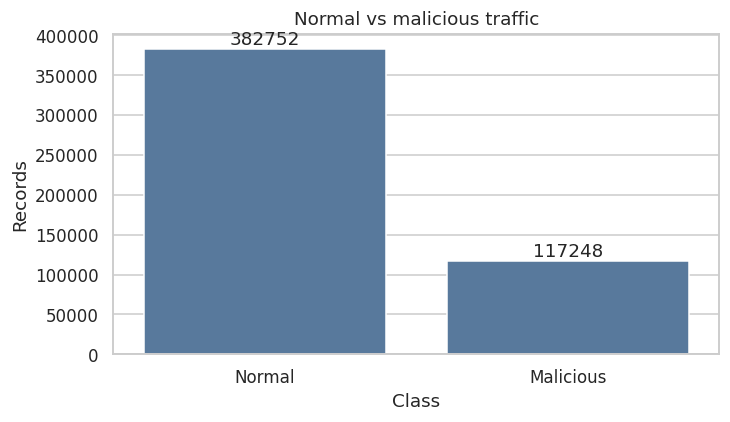

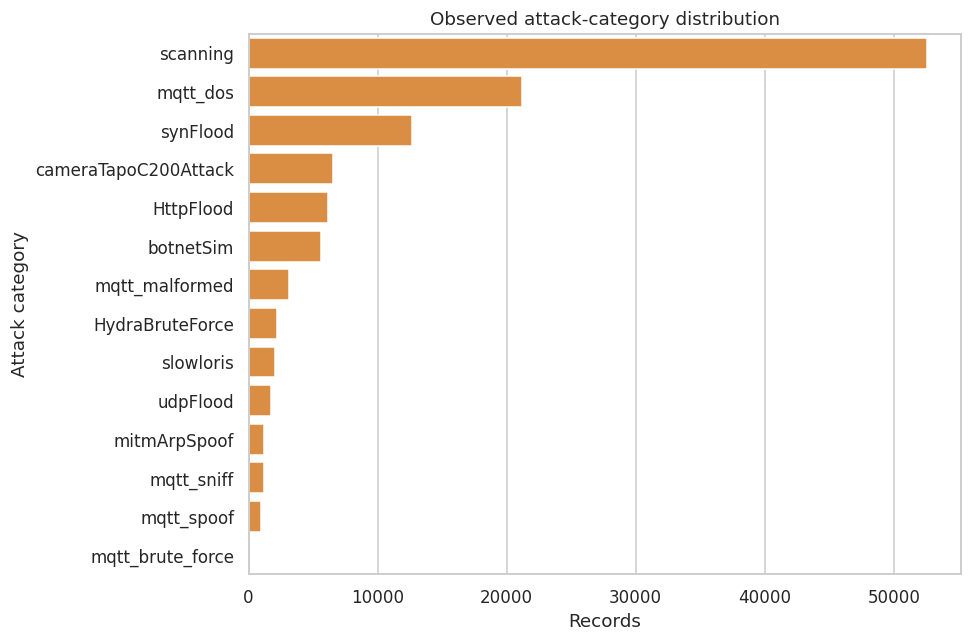

In [3]:
fig, ax=plt.subplots(figsize=(6.8,4)); s=df['attack'].map({0:'Normal',1:'Malicious'}).value_counts();sns.barplot(x=s.index,y=s.values,ax=ax,color='#4C78A8');ax.set(xlabel='Class',ylabel='Records',title='Normal vs malicious traffic');ax.bar_label(ax.containers[0],fmt='%d');plt.xticks(rotation=0);plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,6));a=df.loc[df['attack']==1,'type_of_attack'].value_counts();sns.barplot(x=a.values,y=a.index,ax=ax,color='#F28E2B');ax.set(xlabel='Records',ylabel='Attack category',title='Observed attack-category distribution');plt.tight_layout();plt.show()

## 2. Train/validation/test split and leakage-safe preprocessing
Records are stratified by the binary label, with untouched test data. IDs, attack labels, metadata and timestamp are not model inputs. Split is record-level and thus cannot guarantee separation of related network sessions; this is a methodological limitation.

In [5]:
assert df['attack'].notna().all()
y=df['attack'].astype('int64').to_numpy()
tr_idx,te_idx=train_test_split(np.arange(len(df)),test_size=.20,random_state=SEED,stratify=y)
tr_idx,va_idx=train_test_split(tr_idx,test_size=.20,random_state=SEED,stratify=y[tr_idx])
print('Train / validation / test:',len(tr_idx),len(va_idx),len(te_idx))
DROP={'attack','type_of_attack','uid','ts','orig_h','resp_h','sensor_ip','backup_folder','label_source','window_id','attacker_role','src','dst','client','server','host','uri','query','answers','TTLs','history','uid','md5','sha1','fuid','filename','topic','payload','msg','note','extra','subject','issuer','server_name','user_agent','referrer','weird_addl'}
CATEGORICAL=['proto','service','conn_state','log_type']
NUM_CANDIDATES=['orig_p','resp_p','duration','orig_bytes','resp_bytes','orig_pkts','resp_pkts','orig_ip_bytes','resp_ip_bytes','missed_bytes','qclass','qtype','rcode','request_body_len','response_body_len','status_code','auth_attempts','qos','p','file_duration']
nums=[x for x in NUM_CANDIDATES if x in df and x not in DROP]; cats=[x for x in CATEGORICAL if x in df and x not in DROP]
print('Input numeric:',nums,'| categorical:',cats)
print('Excluded metadata/labels:',sorted(DROP & set(df.columns)))

Train / validation / test: 320000 80000 100000
Input numeric: ['orig_p', 'resp_p', 'duration', 'orig_bytes', 'resp_bytes', 'orig_pkts', 'resp_pkts', 'orig_ip_bytes', 'resp_ip_bytes', 'missed_bytes', 'qclass', 'qtype', 'rcode', 'request_body_len', 'response_body_len', 'status_code', 'auth_attempts', 'qos', 'p', 'file_duration'] | categorical: ['proto', 'service', 'conn_state', 'log_type']
Excluded metadata/labels: ['TTLs', 'answers', 'attack', 'attacker_role', 'backup_folder', 'client', 'dst', 'extra', 'filename', 'fuid', 'history', 'host', 'issuer', 'label_source', 'md5', 'msg', 'note', 'orig_h', 'payload', 'query', 'referrer', 'resp_h', 'sensor_ip', 'server', 'server_name', 'sha1', 'src', 'subject', 'topic', 'ts', 'type_of_attack', 'uid', 'uri', 'user_agent', 'weird_addl', 'window_id']


## 3. Variance-based feature selection
Select up to 32 highest-variance columns from the transformed training subset. This is a top-k operationalization of the paper’s 32-feature target; it does **not** claim to reproduce the paper’s exact threshold or selected names.

Selected 32 features:
                feature  train_variance
           log_type=dns        0.239415
     conn_state=MISSING        0.217342
          log_type=conn        0.217342
              proto=udp        0.207189
              proto=tcp        0.170037
                 orig_p        0.134249
          conn_state=S0        0.119853
         conn_state=REJ        0.108382
        service=MISSING        0.100604
            service=dns        0.079946
          proto=MISSING        0.068764
         log_type=weird        0.034813
          conn_state=SH        0.031344
           service=mqtt        0.022064
         conn_state=OTH        0.021114
      log_type=analyzer        0.015014
  log_type=mqtt_publish        0.009839
                 qclass        0.009794
                  qtype        0.009171
                 resp_p        0.007391
          log_type=http        0.005767
         conn_state=SHR        0.003605
         log_type=files        0.003287
           log_typ

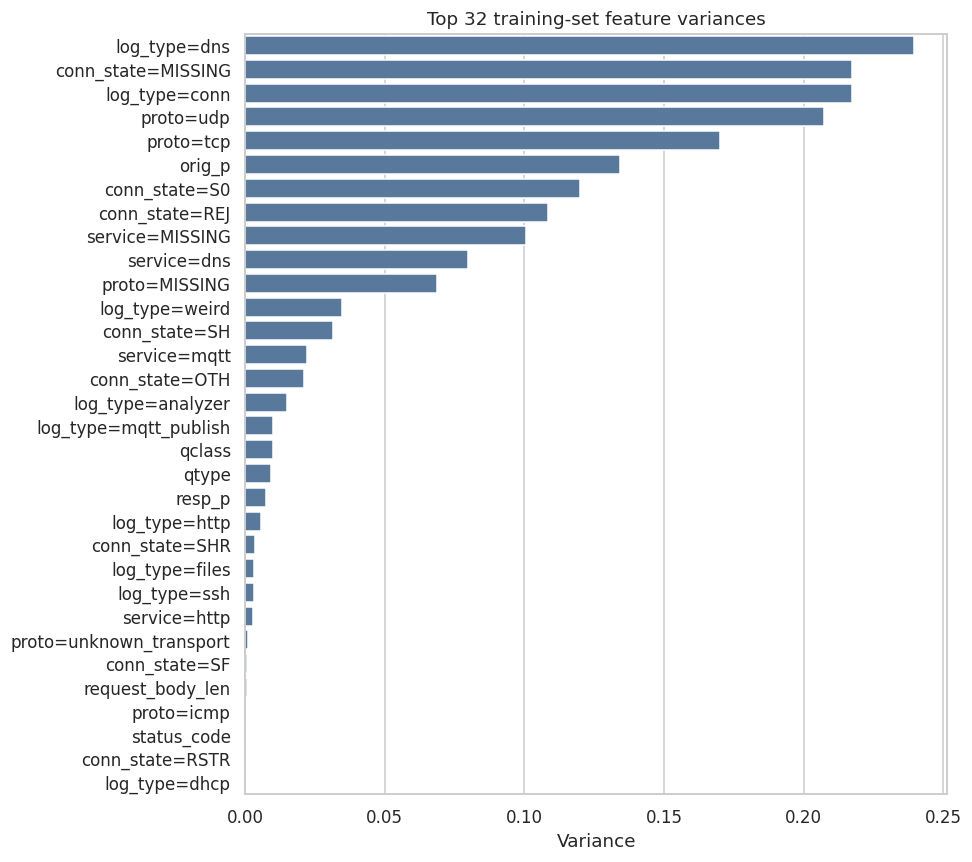

In [7]:
variances=X[tr_idx].var(axis=0)
keep=np.argsort(-variances)[:32]
assert len(keep)==32,'Fewer than 32 encoded fields are available'
X=X[:,keep].copy();selected=[feature_names[i] for i in keep]
selected_variance=variances[keep]
print('Selected 32 features:');print(pd.DataFrame({'feature':selected,'train_variance':selected_variance}).to_string(index=False))
fig,ax=plt.subplots(figsize=(9,8));sns.barplot(x=selected_variance,y=selected,ax=ax,color='#4C78A8');ax.set(title='Top 32 training-set feature variances',xlabel='Variance',ylabel='');plt.tight_layout();plt.show()

## 4. Lightweight source-model training (binary intrusion detection)
The actual dataset does not provide a verified smart-agriculture domain indicator, so this model is trained on the available pooled training records, **not claimed to be an agriculture-source model**. Paper architecture: 32→256→256→128→64→2. A 2-logit softmax-compatible cross-entropy loss is used.

In [9]:
class IDS(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Linear(32,256),nn.ReLU(),nn.Dropout(.2),nn.Linear(256,256),nn.ReLU(),nn.Dropout(.2),nn.Linear(256,128),nn.ReLU(),nn.Dropout(.2))
        self.classifier=nn.Sequential(nn.Linear(128,64),nn.ReLU(),nn.Dropout(.1),nn.Linear(64,2))
    def forward(self,x): return self.classifier(self.features(x))
model=IDS();print(model)
print('Parameter count:',sum(p.numel() for p in model.parameters()))
print('Classifier parameters:',sum(p.numel() for p in model.classifier.parameters()))
print('Frozen share if fine-tuned:',round(100*(1-sum(p.numel() for p in model.classifier.parameters())/sum(p.numel() for p in model.parameters())),2),'%')

IDS(
  (features): Sequential(
    (0): Linear(in_features=32, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
Parameter count: 115522
Classifier parameters: 8386
Frozen share if fine-tuned: 92.74 %


In [ ]:
for ep in range(EPOCHS):
    t0=time.perf_counter();model.train();runloss=0
    for xb,yb in train_loader:
        optimizer.zero_grad();z=model(xb);loss=criterion(z,yb);loss.backward();optimizer.step();runloss+=loss.item()*len(yb)
    model.eval();out=[];truth=[];vloss=0
    with torch.no_grad():
        for xb,yb in val_loader:
            z=model(xb);vloss+=criterion(z,yb).item()*len(yb);out.extend(z.argmax(1).numpy());truth.extend(yb.numpy())
    vf1=f1_score(truth,out,zero_division=0)
    history.append({'epoch':ep+1,'train_loss':runloss/len(train_run_idx),'val_loss':vloss/len(va_idx),'val_f1':vf1,'seconds':time.perf_counter()-t0})
    if vf1>best_f1:best_f1=vf1;best_state=copy.deepcopy(model.state_dict())
    print(f'Epoch {ep+1:02d}: train_loss={history[-1]["train_loss"]:.4f} val_loss={history[-1]["val_loss"]:.4f} val_F1={vf1:.4f} seconds={history[-1]["seconds"]:.1f}',flush=True)
model.load_state_dict(best_state)
print('Best validation F1:',best_f1)

Actual model-training subset: 64000 real records


Epoch 01: train_loss=0.1879 val_loss=0.0578 val_F1=0.9537 seconds=2.4


Epoch 02: train_loss=0.0602 val_loss=0.0585 val_F1=0.9531 seconds=2.1


Best validation F1: 0.9536951855259123


In [ ]:
h=pd.DataFrame(history)
fig,ax=plt.subplots(figsize=(8,4));sns.lineplot(data=h,x='epoch',y='train_loss',marker='o',label='Train',ax=ax);sns.lineplot(data=h,x='epoch',y='val_loss',marker='s',label='Validation',ax=ax);ax.set(title='Observed loss during training',ylabel='Weighted cross-entropy');plt.xticks(rotation=0);plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4));sns.lineplot(data=h,x='epoch',y='val_f1',marker='o',ax=ax);ax.set(title='Validation F1 (actual predictions)',ylabel='F1',ylim=(0,1));plt.xticks(rotation=0);plt.tight_layout();plt.show()

## 5. Held-out binary intrusion detection evaluation

In [ ]:
model.eval();scores=[];actual=[]
with torch.no_grad():
    for xb,yb in test_loader:
        prob=torch.softmax(model(xb),dim=1)[:,1].numpy();scores.extend(prob);actual.extend(yb.numpy())
scores=np.asarray(scores);actual=np.asarray(actual);pred=(scores>=.5).astype(int)
cm=confusion_matrix(actual,pred,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
metrics={'accuracy':accuracy_score(actual,pred),'precision':precision_score(actual,pred,zero_division=0),'recall':recall_score(actual,pred,zero_division=0),'f1':f1_score(actual,pred,zero_division=0),'specificity':tn/(tn+fp),'false_positive_rate':fp/(fp+tn)}
print('Held-out metrics:');print(pd.Series(metrics).round(5).to_string());print(classification_report(actual,pred,target_names=['Normal','Attack'],zero_division=0))
fig,ax=plt.subplots(figsize=(6,5));sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Normal','Attack'],yticklabels=['Normal','Attack'],ax=ax)
ax.set(xlabel='Predicted',ylabel='Actual',title='Held-out test confusion matrix');plt.xticks(rotation=0);plt.tight_layout();plt.show()

In [ ]:
fpr,tpr,_=roc_curve(actual,scores);pr,rc,_=precision_recall_curve(actual,scores)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(fpr,tpr,label=f'ROC AUC = {auc(fpr,tpr):.4f}');ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='False-positive rate',ylabel='True-positive rate',title='Test-set ROC curve');ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(7,4));ax.plot(rc,pr,label=f'PR AUC = {auc(rc[::-1],pr[::-1]):.4f}');ax.set(xlabel='Recall',ylabel='Precision',title='Test-set precision–recall curve',ylim=(0,1.02));ax.legend();plt.tight_layout();plt.show()

## 6. Parameter-efficient classification-layer fine-tuning — demonstration only
Use an isolated subset of pooled training records as fine-tuning examples; keep the test set untouched. This does not demonstrate cross-environment transfer, and its same-distribution performance is not an adaptation gain.

Total parameters: 115522 Trainable classifier parameters: 8386 Frozen: 107136 Trainable reduction %: 92.741


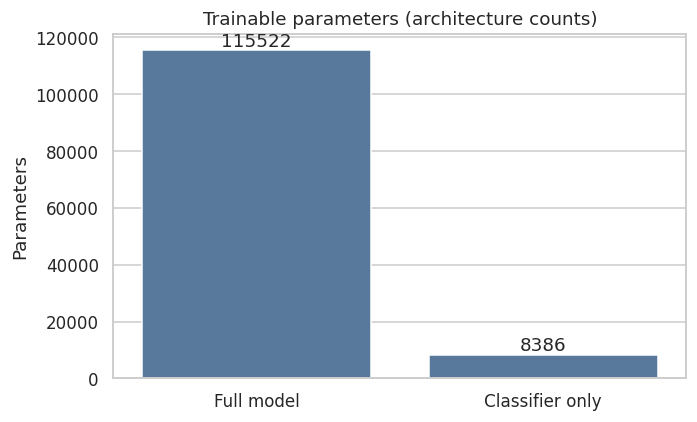

In [14]:
adapt_model=copy.deepcopy(model)
for p in adapt_model.features.parameters(): p.requires_grad=False
fine_indices, _ = train_test_split(tr_idx,test_size=.98,random_state=SEED+1,stratify=y[tr_idx])
opt2=torch.optim.Adam(adapt_model.classifier.parameters(),lr=2e-4)
adapt_model.train();adapt_model.features.eval()
for _ in range(1):
    for xb,yb in loader(fine_indices,batch=1024,shuffle=True):
        opt2.zero_grad();loss=criterion(adapt_model(xb),yb);loss.backward();opt2.step()
full_params=sum(p.numel() for p in adapt_model.parameters());trainable=sum(p.numel() for p in adapt_model.parameters() if p.requires_grad)
print('Total parameters:',full_params,'Trainable classifier parameters:',trainable,'Frozen:',full_params-trainable,'Trainable reduction %:',round(100*(1-trainable/full_params),3))
fig,ax=plt.subplots(figsize=(6.5,4));sns.barplot(x=['Full model','Classifier only'],y=[full_params,trainable],color='#4C78A8',ax=ax);ax.bar_label(ax.containers[0],fmt='%d');ax.set(title='Trainable parameters (architecture counts)',ylabel='Parameters');plt.xticks(rotation=0);plt.tight_layout();plt.show()

## 7. Lightweight resource evaluation — actual model and environment

In [15]:
import io
bio=io.BytesIO();torch.save(model.state_dict(),bio);size_mb=len(bio.getvalue())/1024**2
flops_linear=sum(2*m.in_features*m.out_features for m in model.modules() if isinstance(m,nn.Linear))
model.eval();inp=torch.from_numpy(X[te_idx[:1]])
with torch.no_grad():
    for _ in range(30):model(inp)
    t0=time.perf_counter()
    for _ in range(200):model(inp)
latency_ms=(time.perf_counter()-t0)*1000/200
print('PyTorch state_dict size (MiB):',round(size_mb,4))
print('Approx. linear-layer FLOPs / sample:',flops_linear,'(excludes activations/overheads)')
print('Single-input CPU forward latency (ms):',round(latency_ms,4),'device:',inp.device)
print('Training time (seconds):',round(h['seconds'].sum(),2))

PyTorch state_dict size (MiB): 0.4443
Approx. linear-layer FLOPs / sample: 229632 (excludes activations/overheads)
Single-input CPU forward latency (ms): 0.0817 device: cpu
Training time (seconds): 4.5


## 9. Code-only: adaptation-time measurement

In [ ]:
if torch.cuda.is_available(): torch.cuda.synchronize()
start = time.perf_counter()
for epoch in range(adaptation_epochs):
    for xb, yb in verified_target_adaptation_loader:
        optimizer.zero_grad();loss=criterion(target_model(xb),yb)
        loss.backward();optimizer.step()
if torch.cuda.is_available(): torch.cuda.synchronize()
adaptation_seconds = time.perf_counter() - start
print('Target-domain adaptation time:',adaptation_seconds,'seconds')

## Conclusions and validity boundaries
All executed results are computed from the uploaded CSV. No synthetic samples or fabricated metrics. This notebook experimentally supports the **core binary IDS, feature selection, classifier-only parameter updating, and resource measurement** aspects of the paper. **It does not experimentally establish the cross-domain claim**, adaptation speed, adaptation gain, or 14-class classifier. Actual architecture/efficiency numbers are authoritative over paper placeholders. The source paper’s claimed 30 epochs, 134,400 parameters and other reported results are not assumed reproducible.